In [1]:
import numpy as np
import tifffile
from skophys.sm import NNCCA
from skophys.datasets import ARProcessMovie
import fastplotlib as fpl
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path
import seaborn as sns
from itertools import product

/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
%matplotlib inline

In [3]:
from skimage.transform import downscale_local_mean

In [70]:
parent_path = Path("/home/kushal/lab/datasets/adam_cohen/2/")
frame = tifffile.imread(list(parent_path.glob("*.tiff"))[0])
movie = np.memmap(parent_path.joinpath("frames.bin"), dtype=np.uint16)

xdim, ydim = frame.shape
nframes = movie.size / (xdim * ydim)
assert nframes.is_integer()
nframes = int(nframes)

border_trim = 10

movie = downscale_local_mean(movie.reshape(nframes, xdim, ydim)[3_000:7_000, border_trim:-border_trim, border_trim:-border_trim], (1, 10, 10))[:, :, 40:-20].copy()
xdim = movie.shape[1]
ydim = movie.shape[2]

In [71]:
movie.shape

(4000, 17, 29)

In [72]:
movie_mean = movie.mean(axis=0)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
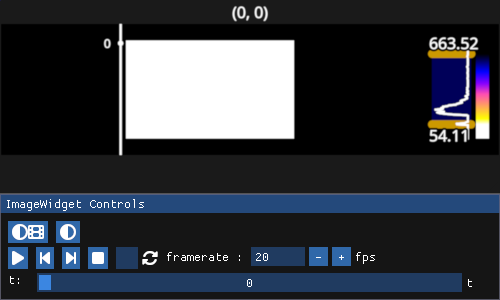

In [73]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2_r", frame_apply={0: lambda f: f - movie_mean})
iw.show()

In [44]:
from dataclasses import dataclass

import numpy as np
import scipy
from tqdm import tqdm

from skophys.preprocessing import Vectorizer, UnVectorizer
from skophys.sm.utils import estimate_n_components_kmeans, nnsvd


@dataclass
class InitArrays:
    Hw: np.ndarray  # whitened vstack([P, F])

    P: np.ndarray   # past lag vectors, not whitened
    F: np.ndarray   # future lag vectors, not whitened

    mu_p: np.ndarray  # mean of the past, shape is [n_pixels]
    mu_f: np.ndarray  # mean of the future, shape is [n_pixels]

    Y: np.ndarray   # output, shape is [k, n_timepoints]

    W: np.ndarray   # W matrix
    W_nw: np.ndarray  # W matrix with non-whitened data projected onto Y
    M: np.ndarray   # M matrix

    k: int                 # number of components
    lag: int
    lag_step: int


class NNSM:
    pass

In [45]:
class BaseSM:
    @property
    def movie(self) -> np.ndarray:
        if self._movie is None:
            raise AttributeError("not pre-initialized yet or pre-initialized without a movie")
        return self._movie

    @property
    def X_init(self) -> np.ndarray:
        if self._X_init is None:
            raise AttributeError(
                "not pre-initialized yet"
            )
        return self._X_init

    @property
    def unvec(self) -> UnVectorizer:
        if self._unvec is None:
            raise AttributeError(
                "not pre-initialized yet or pre-initialized without a movie"
            )
        return self._unvec

    @property
    def n_pixels(self) -> int:
        if self._n_pixels is None:
            raise AttributeError(
                "not pre-initialized yet"
            )
        return self._n_pixels

    @property
    def cov_init(self) -> np.ndarray:
        if self._cov_init is None:
            raise AttributeError("not pre-initialized yet")

        return self._cov_init

    @property
    def pre_init_arrays(self) -> InitArrays:
        if self._pre_init_arrays is None:
            raise AttributeError("not pre-initialized yet")
        return self._pre_init_arrays

    @property
    def init_arrays(self) -> InitArrays:
        if self._init_arrays is None:
            raise AttributeError("not pre-initialized yet")
        return self._init_arrays

    def pre_initialize(self, data: np.ndarray, max_k: int, k: int = None, method: str = "nnsvd"):
        raise NotImplementedError

    def initialize(
            self,
            max_iter: int = 2_000,
            eta: float = 0.1,
            error_threshold: float = 1e-3,
            keep_iteration_results: bool = False,
    ):
        raise NotImplementedError

    def fit_timepoint(self, x_t: np.ndarray):
        raise NotImplementedError


In [46]:
class NNCCA(BaseSM):
    def __init__(
            self,
            lag: int,
            lag_step: int,
    ):
        self._lag: int = lag
        self._lag_step: int = lag_step
        self._lag_slices: list[slice] = None

        self._movie: np.ndarray = None
        self._X_init: np.ndarray = None
        self._unvec: UnVectorizer = None

        self._n_pixels: int = None

        self._cov_init: np.ndarray = None

        self._pre_init_arrays: InitArrays = None
        self._init_arrays: InitArrays = None

    @property
    def lag(self) -> int:
        return self._lag

    @property
    def lag_step(self) -> int:
        return self._lag_step

    @property
    def lag_slices(self) -> list[slice]:
        if self.n_pixels is None:
            raise AttributeError("n_pixels is not set yet, must pre-initialize first")
        return [slice(self.n_pixels * i, (i + 1) * self.n_pixels) for i in range(self.lag * 2)]

    @property
    def movie(self) -> np.ndarray:
        if self._movie is None:
            raise AttributeError("not pre-initialized yet or pre-initialized without a movie")
        return self._movie

    @property
    def X_init(self) -> np.ndarray:
        if self._X_init is None:
            raise AttributeError(
                "not pre-initialized yet"
            )
        return self._X_init

    @property
    def unvec(self) -> UnVectorizer:
        if self._unvec is None:
            raise AttributeError(
                "not pre-initialized yet or pre-initialized without a movie"
            )
        return self._unvec

    @property
    def n_pixels(self) -> int:
        if self._n_pixels is None:
            raise AttributeError(
                "not pre-initialized yet"
            )
        return self._n_pixels

    @property
    def cov_init(self) -> np.ndarray:
        if self._cov_init is None:
            raise AttributeError("not pre-initialized yet")

        return self._cov_init

    @property
    def pre_init_arrays(self) -> InitArrays:
        if self._pre_init_arrays is None:
            raise AttributeError("not pre-initialized yet")
        return self._pre_init_arrays

    @property
    def init_arrays(self) -> InitArrays:
        if self._init_arrays is None:
            raise AttributeError("not pre-initialized yet")
        return self._init_arrays

    def pre_initialize(self, data: np.ndarray, max_k: int, k: int = None, method: str = "nnsvd"):
        """
        Run nnSVD to pre-initialize Y before initializing with gradient descent.

        Parameters
        ----------
        data: data to initialize with, shape of [n_timepoints, rows, cols] or [n_pixels, n_timepoints]

        method: only "nnsvd" for now

        """
        if data.ndim == 3:
            self._movie = data
            self._X_init = Vectorizer().transform(self.movie)
            self._unvec = UnVectorizer(self.movie.shape[1:])
        elif data.ndim == 2:
            self._X_init = data
        else:
            raise ValueError("`data` ndim must be 2 or 3")

        if self.X_init.shape[0] * self.lag > self.X_init.shape[1]:
            raise ValueError(
                f"(n_pixels * lag) > timepoints. Require more timepoints to initialize\n"
                f"X_init shape: {self.X_init.shape}"
            )

        self._n_pixels = self._X_init.shape[0]

        if method != "nnsvd":
            raise ValueError("only nnsvd supported for now")

        Hs = list()

        print("creating H")
        for i in range(self.n_pixels):
            Hs.append(
                scipy.linalg.hankel(
                    self.X_init[i, : self.lag * self.lag_step * 2], self.X_init[i, (self.lag * self.lag_step * 2) - 1 :]
                )[::self.lag_step]
            )

        H = np.zeros((self.lag * 2 * self.n_pixels, self.X_init.shape[1] - (self.lag * self.lag_step * 2) + 1))
        for i, H_i in enumerate(Hs):
            H[i::self.n_pixels] = H_i

        mu0 = H[: self.lag * self.n_pixels].mean(axis=1)
        mu1 = H[self.lag * self.n_pixels :].mean(axis=1)

        H[: self.lag * self.n_pixels] -= mu0[:, None]
        H[self.lag * self.n_pixels :] -= mu1[:, None]

        past = H[: self.lag * self.n_pixels]
        future = H[self.lag * self.n_pixels :]

        print("Whitening H")
        Hw = np.vstack(
            [
                scipy.linalg.pinv(scipy.linalg.sqrtm(past @ past.T / past.shape[1])) @ past,
                scipy.linalg.pinv(scipy.linalg.sqrtm(future @ future.T / future.shape[1])) @ future,
            ]
        )

        print("computing covariance")
        cov = Hw.T @ Hw

        self._cov_init = cov / np.linalg.norm(cov, ord="fro")
        
        if k is None:
            print("estimating k")
            k = estimate_n_components_kmeans(
                H_nw=np.vstack([past, future]),
                max_k=max_k,
            )

        print("performing nnSVD")
        _, Y = nnsvd(A=self.cov_init, k=k)

        self._pre_init_arrays = InitArrays(
            Hw=Hw,
            P=past,
            F=future,
            mu_p=mu0,
            mu_f=mu1,
            Y=Y,
            k=k,
            lag=self.lag,
            lag_step=self.lag_step,
            W=None,
            W_nw=None,
            M=None,
        )

    def initialize(
            self,
            max_iter: int = 2_000,
            eta: float = 0.1,
            error_threshold: float = 1e-3,
            keep_iteration_results: bool = False,
    ):
        if self._pre_init_arrays is None:
            raise AttributeError("Must pre-initialize first")

        Y = self._pre_init_arrays.Y.copy()

        # T = self.cov_init.shape[0]

        error_log = list()

        Ys = list()
        Ws = list()

        for iteration in tqdm(range(max_iter)):
            if keep_iteration_results:
                Ys.append(Y)
                Ws.append(Y @ self.cov_init.T)

            # if iteration > 500:
            #     eta = 1.0
            # if iteration > 1_000:
            #     eta = 0.5

            Y_old = Y
            Y = Y + eta * Y @ (self.cov_init - Y.T @ Y)

            # zeroed = Y.sum(axis=1) == 0.0
            # Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)

            Y = Y.clip(0)

            er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
            error_log.append(er)
            if er < error_threshold:
                break

        H_nw = np.vstack([self._pre_init_arrays.P, self._pre_init_arrays.F])

        W = Y @ self._pre_init_arrays.Hw.T  # / sum_y_squared
        W_nw = Y @ H_nw.T  # / sum_y_squared
        M = Y @ Y.T  # / sum_y_squared

        self._init_arrays = InitArrays(
            Hw=self._pre_init_arrays.Hw,
            P=self._pre_init_arrays.P,
            F=self._pre_init_arrays.F,
            mu_p=self._pre_init_arrays.mu_p,
            mu_f=self._pre_init_arrays.mu_f,
            Y=Y,
            k=self._pre_init_arrays.k,
            lag=self.lag,
            lag_step=self.lag_step,
            W=W,
            W_nw=W_nw,
            M=M,
        )

        return error_log, Ys, Ws

    def fit_timepoint(self, x_t: np.ndarray):
        """

movie = downscale_local_mean(movie.reshape(nframes, xdim, ydim)[3_000:7_000, border_trim:-border_trim, border_trim:-border_trim], (1, 12, 12))[:, :, 40:-20].copy()
        Parameters
        ----------
        x_t: vector of shape [n_pixels]

        Returns
        -------

        """
        pass

In [104]:
nncca = NNCCA(lag=3, lag_step=1)

In [105]:
nncca.pre_initialize(movie, max_k=10)

creating H
Whitening H
computing covariance
estimating k
performing nnSVD


In [114]:
nncca.cov_init.shape

(3995, 3995)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
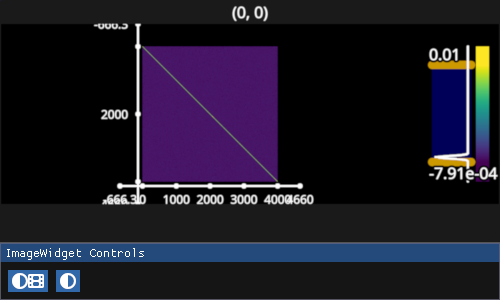

In [115]:
cov_iw = fpl.ImageWidget(nncca.cov_init, cmap="viridis")
cov_iw.show()

In [106]:
nncca._X_init.shape

(493, 4000)

In [107]:
nncca.pre_init_arrays.Hw.shape

(2958, 3995)

In [108]:
nncca.pre_init_arrays.Y

array([[0.00350057, 0.00236948, 0.0001289 , ..., 0.00040585, 0.0027798 ,
        0.00079668],
       [0.00045589, 0.        , 0.        , ..., 0.        , 0.00191061,
        0.00402069],
       [0.00082967, 0.00408671, 0.        , ..., 0.00030699, 0.        ,
        0.        ],
       [0.00354928, 0.00010494, 0.        , ..., 0.00079087, 0.        ,
        0.00160947]])

In [109]:
err_log, Ys, Ws =  nncca.initialize(max_iter=6_000, keep_iteration_results=True, eta=0.5)

 21%|████████████████████████▉                                                                                             | 1265/6000 [01:14<04:37, 17.09it/s]


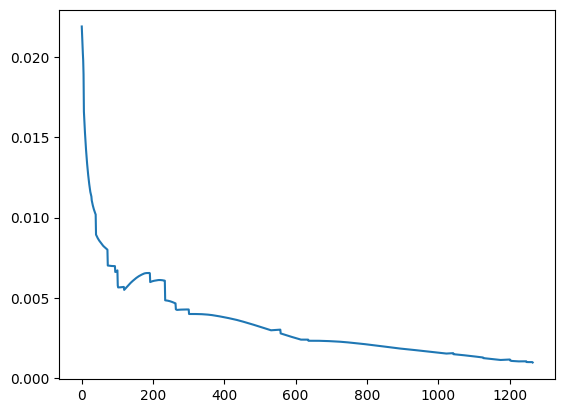

In [110]:
plt.plot(err_log)

<Axes: >

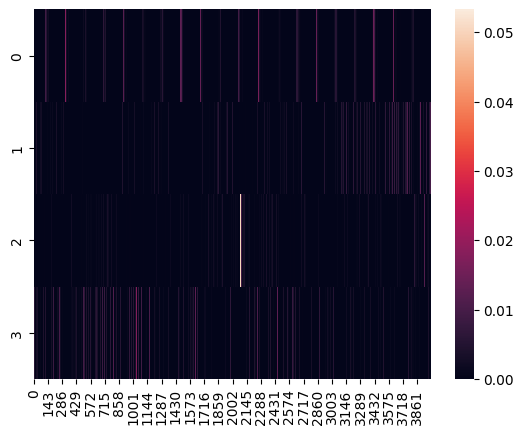

In [111]:
sns.heatmap(nncca.init_arrays.Y)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
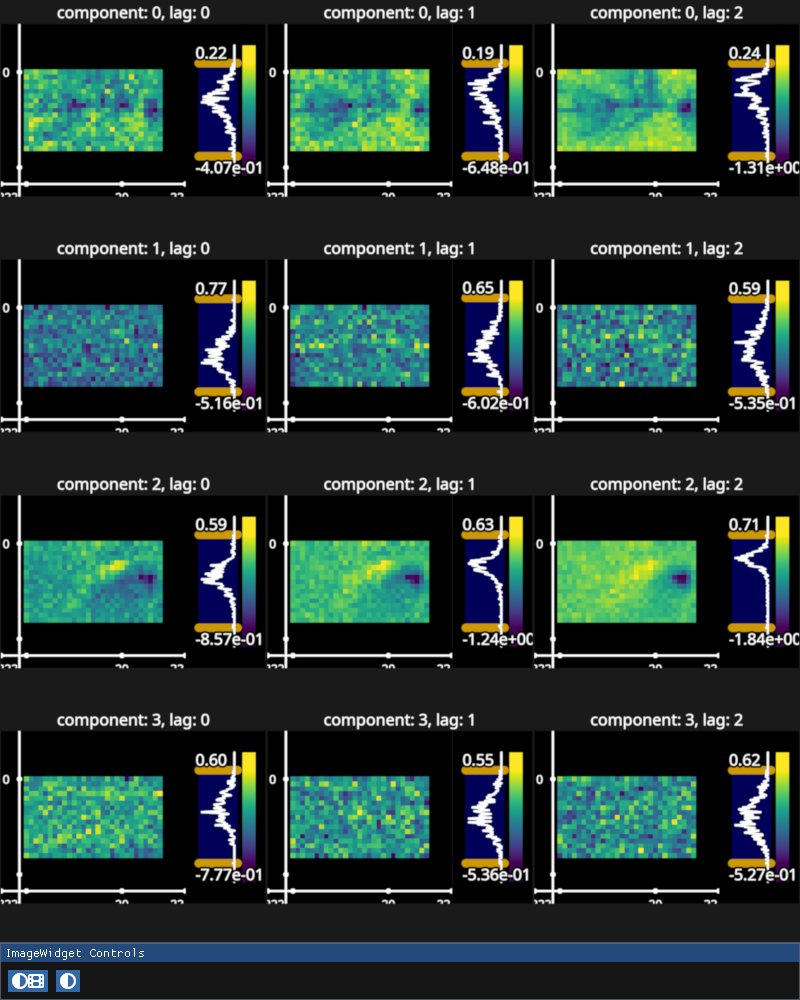

In [112]:
images, titles = list(), list(),
for k_i, l_i in product(range(nncca.init_arrays.k), range(nncca.lag)):
    images.append(nncca.unvec.transform(nncca.init_arrays.W[k_i, nncca.lag_slices[l_i]].T))
    titles.append(f"component: {k_i}, lag: {l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(nncca.init_arrays.k, nncca.lag),
    figure_kwargs={"size": (800, 1000)},
)

# for g in iw_W.managed_graphics:
#     g.vmin = 0

iw_W.show()

RFBOutputContext()

JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
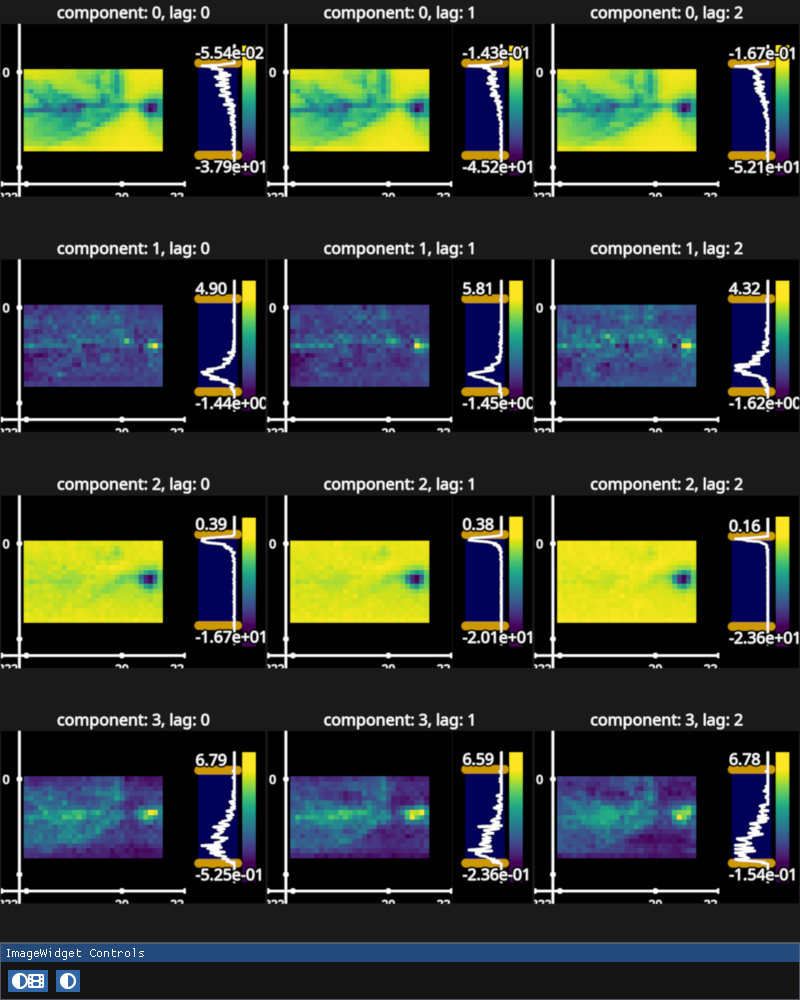

In [113]:
images, titles = list(), list(),
for k_i, l_i in product(range(nncca.init_arrays.k), range(nncca.lag)):
    images.append(nncca.unvec.transform(nncca.init_arrays.W_nw[k_i, nncca.lag_slices[l_i]].T))
    titles.append(f"component: {k_i}, lag: {l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(nncca.init_arrays.k, nncca.lag),
    figure_kwargs={"size": (800, 1000)},
)

# for g in iw_W.managed_graphics:
#     g.vmin = 0

iw_W.show()